# FMA Music Genre Clustering & CNN Classification

This notebook analyzes genre structure in the Free Music Archive (FMA) dataset using audio features.

## Overview:
1. Audio Feature Extraction
2. Genre-based Feature Analysis
3. Audio Visualization (Waveforms, Mel Spectrograms, MFCCs)
4. Feature Distribution Analysis
5. Clustering with **PCA → t-SNE**
6. **CNN Genre Classification** (target test accuracy **> 0.70**)


## 1. Setup and Import Libraries

In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import warnings
import pickle
from pathlib import Path
from IPython.display import Audio, display
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

print('Libraries imported successfully!')
print(f'TensorFlow version: {tf.__version__}')


Libraries imported successfully!
TensorFlow version: 2.21.0


## 2. Load Dataset

In [3]:
# Define paths
PROJECT_ROOT = Path(r'C:\HKBU_FYP')
PROCESSED_ROOT = PROJECT_ROOT / 'processed'
METADATA_ROOT = PROJECT_ROOT / 'dataset' / 'fma_metadata'
DATA_PATH = PROCESSED_ROOT / 'fma_small_analysis.csv'

# Load dataset
df = pd.read_csv(DATA_PATH)

print(f'Dataset loaded: {len(df)} tracks')
print(f'Columns: {list(df.columns)}')
print(f'\nFirst few rows:')
display(df.head())


Dataset loaded: 8000 tracks
Columns: ['track_id', 'title', 'artist', 'genre', 'duration', 'listens', 'interest', 'audio_path']

First few rows:


,track_id,title,artist,genre,duration,listens,interest,audio_path
0,2,Food,AWOL,Hip-Hop,168,1293,4656,C:\HKBU_FYP\dataset\fma_small\000\000002.mp3
1,5,This World,AWOL,Hip-Hop,206,1151,1933,C:\HKBU_FYP\dataset\fma_small\000\000005.mp3
2,10,Freeway,Kurt Vile,Pop,161,50135,54881,C:\HKBU_FYP\dataset\fma_small\000\000010.mp3
3,140,Queen Of The Wires,Alec K. Redfearn & the Eyesores,Folk,253,1299,1593,C:\HKBU_FYP\dataset\fma_small\000\000140.mp3
4,141,Ohio,Alec K. Redfearn & the Eyesores,Folk,182,725,839,C:\HKBU_FYP\dataset\fma_small\000\000141.mp3


In [4]:
# Genre distribution
genre_counts = df['genre'].value_counts()
print('Genre Distribution:\n')
print(genre_counts)

# Remove Unknown genre for classification
df_clean = df[df['genre'] != 'Unknown'].copy()
print(f'\nDataset after removing Unknown: {len(df_clean)} tracks')
print(f'Number of genres: {df_clean["genre"].nunique()}')

Genre Distribution:

genre
Hip-Hop          1000
Pop              1000
Folk             1000
Experimental     1000
Rock             1000
International    1000
Electronic       1000
Instrumental     1000
Name: count, dtype: int64

Dataset after removing Unknown: 8000 tracks
Number of genres: 8


## 3. Audio Feature Extraction

We'll extract various audio features commonly used in music genre classification:
- **Spectral Features**: Spectral centroid, bandwidth, rolloff
- **Chroma Features**: Pitch class profiles
- **Zero Crossing Rate**: Rate of sign changes in signal
- **MFCCs**: Mel-Frequency Cepstral Coefficients (20 coefficients)
- **Tempo**: Beats per minute
- **RMS Energy**: Root mean square energy

In [5]:
def extract_features(audio_path, sr=22050, duration=30):
    """
    Extract comprehensive audio features from a music file
    
    Parameters:
    - audio_path: Path to audio file
    - sr: Sample rate (default 22050 Hz)
    - duration: Maximum duration to load (seconds)
    
    Returns:
    - Dictionary of extracted features
    """
    try:
        # Load audio
        y, sr = librosa.load(audio_path, sr=sr, duration=duration, mono=True)
        
        # Initialize feature dictionary
        features = {}
        
        # 1. Spectral Centroid (brightness of sound)
        spectral_centroids = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
        features['spectral_centroid_mean'] = np.mean(spectral_centroids)
        features['spectral_centroid_std'] = np.std(spectral_centroids)
        
        # 2. Spectral Rolloff (frequency below which certain percentage of energy is contained)
        spectral_rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)[0]
        features['spectral_rolloff_mean'] = np.mean(spectral_rolloff)
        features['spectral_rolloff_std'] = np.std(spectral_rolloff)
        
        # 3. Spectral Bandwidth
        spectral_bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)[0]
        features['spectral_bandwidth_mean'] = np.mean(spectral_bandwidth)
        features['spectral_bandwidth_std'] = np.std(spectral_bandwidth)
        
        # 4. Zero Crossing Rate
        zcr = librosa.feature.zero_crossing_rate(y)[0]
        features['zcr_mean'] = np.mean(zcr)
        features['zcr_std'] = np.std(zcr)
        
        # 5. Chroma Features (12 pitch classes)
        chroma_stft = librosa.feature.chroma_stft(y=y, sr=sr)
        features['chroma_mean'] = np.mean(chroma_stft)
        features['chroma_std'] = np.std(chroma_stft)
        
        # 6. RMS Energy
        rms = librosa.feature.rms(y=y)[0]
        features['rms_mean'] = np.mean(rms)
        features['rms_std'] = np.std(rms)
        
        # 7. MFCCs (Mel-Frequency Cepstral Coefficients) - 20 coefficients
        mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
        for i in range(20):
            features[f'mfcc{i+1}_mean'] = np.mean(mfccs[i])
            features[f'mfcc{i+1}_std'] = np.std(mfccs[i])
        
        # 8. Tempo (BPM)
        try:
            tempo, _ = librosa.beat.beat_track(y=y, sr=sr)
            # Handle both scalar and array tempo values from different librosa versions
            features['tempo'] = float(np.asarray(tempo).flatten()[0])
        except Exception as tempo_error:
            # If tempo detection fails, set a default value
            features['tempo'] = 120.0
            print(f'Warning: Could not detect tempo for {audio_path}, using default 120 BPM')
        
        return features
        
    except Exception as e:
        print(f'Error processing {audio_path}: {str(e)}')
        return None

print('Feature extraction function defined!')

Feature extraction function defined!


In [6]:
# Extract features from a sample of tracks (for demonstration)
# NOTE: Full extraction takes time. Adjust SAMPLE_SIZE as needed.
SAMPLE_SIZE = 800  # Medium set is larger; raise further if needed

# Select balanced sample across genres
per_genre_size = SAMPLE_SIZE // df_clean['genre'].nunique()
sample_list = []
for genre in df_clean['genre'].unique():
    genre_data = df_clean[df_clean['genre'] == genre]
    sample_size = min(len(genre_data), per_genre_size)
    sample_list.append(genre_data.sample(n=sample_size, random_state=42))

sample_df = pd.concat(sample_list, ignore_index=True)

print(f'Extracting features from {len(sample_df)} tracks...')
print('This may take a few minutes...\n')

# Extract features
features_list = []
for idx in range(len(sample_df)):
    if idx % 10 == 0:
        print(f'Processing track {idx+1}/{len(sample_df)}...')
    
    row = sample_df.iloc[idx]
    features = extract_features(row['audio_path'])
    if features:
        features['track_id'] = int(row['track_id'])
        features['genre'] = str(row['genre'])
        features['title'] = str(row['title'])
        features['artist'] = str(row['artist'])
        features_list.append(features)

# Create features dataframe
features_df = pd.DataFrame(features_list)

print(f'\nFeature extraction complete!')
print(f'Features extracted: {len(features_df)} tracks')
print(f'Number of features: {len(features_df.columns) - 4}')

# Save features
output_path = PROCESSED_ROOT / 'genre_classification_features.csv'
features_df.to_csv(output_path, index=False)
print(f'\nFeatures saved to: {output_path}')

Extracting features from 800 tracks...
This may take a few minutes...

Processing track 1/800...


Processing track 11/800...
Processing track 21/800...
Processing track 31/800...
Processing track 41/800...
Processing track 51/800...
Processing track 61/800...
Processing track 71/800...
Processing track 81/800...
Processing track 91/800...
Processing track 101/800...
Processing track 111/800...
Processing track 121/800...
Processing track 131/800...
Processing track 141/800...
Processing track 151/800...
Processing track 161/800...
Processing track 171/800...
Processing track 181/800...
Processing track 191/800...
Processing track 201/800...
Processing track 211/800...
Processing track 221/800...
Processing track 231/800...
Processing track 241/800...
Processing track 251/800...
Processing track 261/800...
Processing track 271/800...
Processing track 281/800...
Processing track 291/800...
Processing track 301/800...
Processing track 311/800...
Processing track 321/800...
Processing track 331/800...
Processing track 341/800...
Processing track 351/800...
Processing track 361/800...
P

In [7]:
# Display sample features
print('Sample of extracted features:')
display(features_df.head())

print('\nFeature statistics:')
display(features_df.describe())

Sample of extracted features:


,spectral_centroid_mean,spectral_centroid_std,spectral_rolloff_mean,spectral_rolloff_std,spectral_bandwidth_mean,spectral_bandwidth_std,zcr_mean,zcr_std,chroma_mean,chroma_std,...,mfcc18_std,mfcc19_mean,mfcc19_std,mfcc20_mean,mfcc20_std,tempo,track_id,genre,title,artist
0,2306.787327,900.155145,4973.319269,1910.853973,2440.218448,547.265466,0.094813,0.064324,0.499354,0.295956,...,6.466883,-3.455165,6.351714,1.394112,5.994504,129.199219,89848,Hip-Hop,Not the 1s (prod. by Mexicans with Guns),Not The 1s
1,1891.511697,742.959599,4303.915641,1817.260696,2277.756664,484.778324,0.068317,0.037533,0.367160,0.289411,...,7.106272,-2.518176,7.821215,2.786639,8.180317,99.384014,114268,Hip-Hop,poison ivy yard work,Uncle Milk
2,1666.913707,671.269901,3431.154252,1548.687987,1936.506849,448.163185,0.066884,0.038441,0.359882,0.304441,...,9.960264,-8.642042,9.024205,-1.620751,8.737236,143.554688,114275,Hip-Hop,eat it with a fork,Uncle Milk
3,1239.691602,469.651885,2698.664110,1265.371138,1843.636459,361.166485,0.033932,0.018851,0.490753,0.291859,...,3.842575,-0.482394,4.500822,0.199638,4.171955,143.554688,108841,Hip-Hop,Head Cold,Tha Silent Partner
4,1187.406665,654.831389,2775.049886,2129.929129,1902.347378,590.399347,0.023178,0.017172,0.461165,0.325075,...,8.822106,-2.683877,6.315767,-1.923011,5.577920,92.285156,72785,Hip-Hop,Give Her The Length/Give It 2 Her 2times (XXX ...,Tha Silent Partner



Feature statistics:


,spectral_centroid_mean,spectral_centroid_std,spectral_rolloff_mean,spectral_rolloff_std,spectral_bandwidth_mean,spectral_bandwidth_std,zcr_mean,zcr_std,chroma_mean,chroma_std,...,mfcc17_mean,mfcc17_std,mfcc18_mean,mfcc18_std,mfcc19_mean,mfcc19_std,mfcc20_mean,mfcc20_std,tempo,track_id
count,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,...,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.00000
mean,1898.112303,626.186909,3916.044794,1349.746070,2085.996860,412.327153,0.084126,0.041894,0.375068,0.290531,...,-4.172219,7.191648,-0.174642,7.250190,-3.512541,7.436155,-0.555011,7.528761,120.304227,82745.33125
std,712.065145,310.182610,1558.980694,622.102371,556.365371,177.708285,0.044197,0.026002,0.097778,0.020282,...,5.073937,2.095623,4.763886,2.129319,4.664634,2.347630,4.969815,2.480363,29.359543,43162.64098
min,222.398542,54.895361,394.822613,102.965699,224.755426,49.509794,0.008099,0.002635,0.042962,0.113285,...,-24.339500,2.878818,-15.812252,2.269131,-19.667948,2.280345,-19.335253,2.578007,0.000000,210.00000
25%,1426.474745,392.710382,2913.843941,877.500920,1758.278318,279.239610,0.053449,0.024034,0.303647,0.284162,...,-7.049389,5.714226,-3.013308,5.771123,-6.172092,5.871104,-3.325034,5.833474,99.384014,48462.25000
50%,1877.217789,598.017281,3963.188535,1344.005787,2174.075354,400.970683,0.075500,0.036410,0.369830,0.293001,...,-4.006314,6.932675,0.154517,6.941803,-3.302840,7.097775,-0.232064,7.079639,117.453835,89464.50000
75%,2359.176936,826.331902,4926.957667,1798.740467,2487.258475,521.538708,0.104002,0.052836,0.433427,0.301049,...,-0.982705,8.164785,2.914378,8.207755,-0.742610,8.459473,2.449801,8.783152,135.999178,120124.50000
max,5102.468891,1789.580359,8691.432933,3133.112009,3334.625149,1031.775048,0.432662,0.215885,0.838345,0.368666,...,13.774528,17.185307,15.852467,18.519352,25.190893,21.110542,18.973669,28.514107,215.332031,154413.00000


## 4. Audio Visualization

Visualize audio characteristics for different genres to make them easier to identify:
1. **Waveform + beats/RMS** — dynamics & rhythm density
2. **Mel Spectrogram** — bass vs brightness (with centroid / rolloff)
3. **Chromagram** — harmony / pitch-class variety
4. **MFCC** — timbre texture (key features for classification)


In [8]:
def visualize_audio(audio_path, title="Audio Analysis", duration=30, win_length=1024):
    """
    Genre-oriented audio visualization (4 panels).
    Uses reference STFT window settings (win_length=1024, 50% hop),
    with perceptual / MIR cues that make genres easier to tell apart.
    """
    y, sr = librosa.load(audio_path, sr=22050, duration=duration, mono=True)
    hop_length = win_length // 2

    # ---- Genre-discriminative summary stats ----
    peak = float(np.max(np.abs(y)))
    rms = float(np.sqrt(np.mean(y ** 2)))
    crest = peak / (rms + 1e-9)  # high = dynamic; low = compressed/loud
    cent = librosa.feature.spectral_centroid(y=y, sr=sr, hop_length=hop_length)[0]
    bw = librosa.feature.spectral_bandwidth(y=y, sr=sr, hop_length=hop_length)[0]
    roll = librosa.feature.spectral_rolloff(y=y, sr=sr, hop_length=hop_length)[0]
    zcr = librosa.feature.zero_crossing_rate(y, hop_length=hop_length)[0]
    try:
        tempo, beat_frames = librosa.beat.beat_track(y=y, sr=sr, hop_length=hop_length)
        tempo = float(np.asarray(tempo).flatten()[0])
        beat_times = librosa.frames_to_time(beat_frames, sr=sr, hop_length=hop_length)
    except Exception:
        tempo, beat_times = 120.0, np.array([])

    cent_m = float(cent.mean())
    bw_m = float(bw.mean())
    roll_m = float(roll.mean())
    zcr_m = float(zcr.mean())

    fig, axes = plt.subplots(4, 1, figsize=(15, 22))
    fig.suptitle(
        f'{title}\n'
        f'Tempo={tempo:.0f} BPM | Centroid={cent_m:.0f} Hz | Bandwidth={bw_m:.0f} Hz | '
        f'Rolloff={roll_m:.0f} Hz | ZCR={zcr_m:.3f} | Crest={crest:.2f}',
        fontsize=12, fontweight='bold', y=1.01
    )

    # ========== 1. Waveform + RMS + onsets/beats ==========
    ylim_max = max(peak * 1.5, 0.1)
    librosa.display.waveshow(y, sr=sr, ax=axes[0], color='steelblue', alpha=0.75)
    rms_env = librosa.feature.rms(y=y, frame_length=win_length, hop_length=hop_length)[0]
    rms_times = librosa.frames_to_time(np.arange(len(rms_env)), sr=sr, hop_length=hop_length)
    axes[0].plot(rms_times, rms_env, color='darkorange', lw=1.8, label='RMS envelope')
    axes[0].plot(rms_times, -rms_env, color='darkorange', lw=1.8)
    # Beat markers → rhythmic density (Electronic/Hip-Hop vs ambient/classical)
    if len(beat_times) > 0:
        axes[0].vlines(
            beat_times, -ylim_max, ylim_max,
            color='crimson', alpha=0.25, lw=0.8,
            label=f'Beats (n={len(beat_times)})'
        )
    axes[0].set_ylim(-ylim_max, ylim_max)
    axes[0].set_xlim(0, len(y) / sr)
    axes[0].set_title(
        f'1. Waveform + dynamics  |  Peak={peak:.3f}  RMS={rms:.3f}  '
        f'Crest={crest:.2f} (high=dynamic, low=loud/compressed)'
    )
    axes[0].set_xlabel('Time (s)')
    axes[0].set_ylabel('Amplitude')
    axes[0].legend(loc='upper right', fontsize=9)
    axes[0].grid(True, alpha=0.3)

    # ========== 2. Mel spectrogram (better than linear-Hz for genre) ==========
    mel = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=win_length, hop_length=hop_length, n_mels=128, fmax=sr // 2
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)
    img = librosa.display.specshow(
        mel_db, sr=sr, hop_length=hop_length,
        x_axis='time', y_axis='mel', ax=axes[1],
        cmap=plt.get_cmap('magma'), vmin=mel_db.max() - 80
    )
    times = librosa.frames_to_time(np.arange(len(cent)), sr=sr, hop_length=hop_length)
    axes[1].plot(times, cent, color='cyan', lw=1.5, label='Spectral centroid')
    axes[1].plot(times, roll, color='lime', lw=1.2, alpha=0.9, label='Spectral rolloff')
    axes[1].legend(loc='upper right', fontsize=9)
    axes[1].set_title(
        f'2. Mel Spectrogram  |  win={win_length}, shape={mel_db.shape}  |  '
        f'Brightness: centroid={cent_m:.0f} Hz'
    )
    axes[1].set_ylabel('Mel Hz')
    fig.colorbar(img, ax=axes[1], format='%+2.0f dB').set_label('dB')

    # ========== 3. Chromagram + harmonic focus ==========
    chroma = librosa.feature.chroma_cqt(y=y, sr=sr, hop_length=hop_length)
    img = librosa.display.specshow(
        chroma, sr=sr, hop_length=hop_length,
        x_axis='time', y_axis='chroma', ax=axes[2],
        cmap=plt.get_cmap('coolwarm'), vmin=0, vmax=1
    )
    pitch_names = np.array(['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B'])
    chroma_mean = chroma.mean(axis=1)
    top3 = pitch_names[np.argsort(chroma_mean)[-3:][::-1]]
    chroma_std = float(chroma.std())
    axes[2].set_title(
        f'3. Chromagram (harmony)  |  Top pitches: {", ".join(top3)}  |  '
        f'Var={chroma_std:.3f} (high=Jazz/Classical; low=more static harmony)'
    )
    fig.colorbar(img, ax=axes[2], label='Energy')

    # ========== 4. MFCC (timbre — strongest genre cue) ==========
    n_mfcc = 13
    mfccs = librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=n_mfcc, n_fft=win_length, hop_length=hop_length
    )
    mfccs_disp = mfccs - np.mean(mfccs, axis=1, keepdims=True)
    vlim = float(np.percentile(np.abs(mfccs_disp), 99)) + 1e-6
    img = librosa.display.specshow(
        mfccs_disp, sr=sr, hop_length=hop_length,
        x_axis='time', ax=axes[3],
        cmap=plt.get_cmap('RdBu_r'), vmin=-vlim, vmax=vlim
    )
    axes[3].set_yticks(np.arange(n_mfcc))
    axes[3].set_yticklabels([f'MFCC{i+1}' for i in range(n_mfcc)])
    axes[3].set_title(
        f'4. MFCC timbre (mean-centered)  |  shape={mfccs.shape}  |  '
        f'Lower coeffs = genre / instrument texture'
    )
    axes[3].set_ylabel('Coefficient')
    fig.colorbar(img, ax=axes[3], label='Centered value')

    cue = (
        'Genre tips:  Hip-Hop/Electronic → dense beats, high RMS, bass-heavy mel;  '
        'Classical/Jazz → higher crest (dynamics), richer chroma variation;  '
        'Rock → mid/high energy, dense MFCC texture'
    )
    fig.text(0.5, -0.01, cue, ha='center', fontsize=9, style='italic', color='#333333')

    plt.tight_layout()
    plt.show()

    print(
        f'Genre cues → tempo={tempo:.0f}, centroid={cent_m:.0f}Hz, '
        f'crest={crest:.2f}, chroma_var={chroma_std:.3f}, top_pitches={list(top3)}'
    )

print('Audio visualization function defined!')


Audio visualization function defined!


Comparing genres: ['Hip-Hop', 'Pop', 'Folk', 'Experimental', 'Rock']
Look for differences in: beats/RMS (rhythm), mel bass/brightness, chroma variety, MFCC texture


Visualizing: Not The 1s - Not the 1s (prod. by Mexicans with Guns) (Hip-Hop)


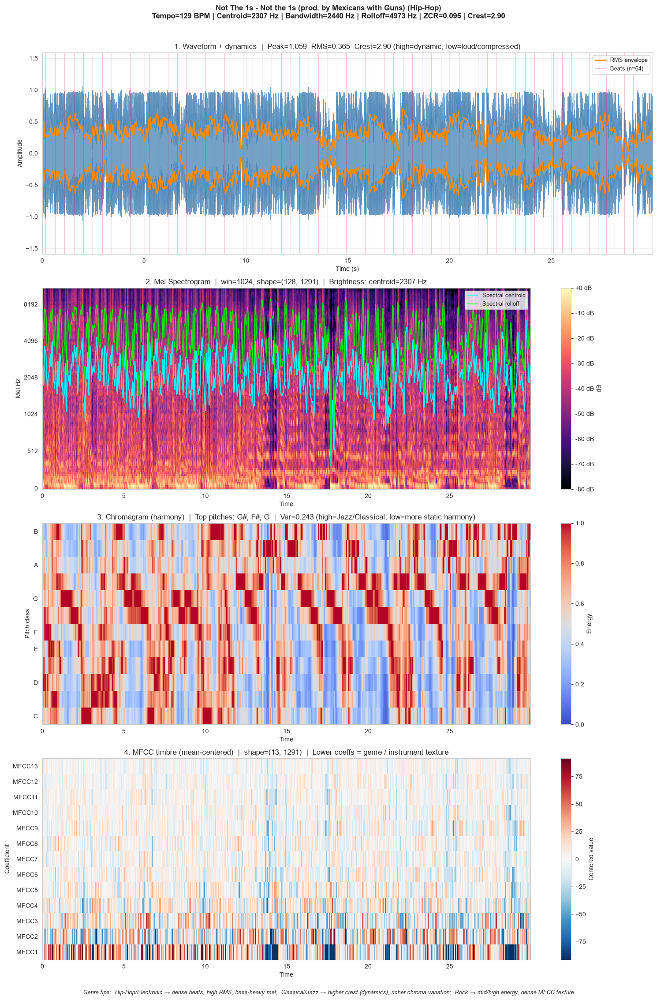

Genre cues → tempo=129, centroid=2307Hz, crest=2.90, chroma_var=0.243, top_pitches=[np.str_('G#'), np.str_('F#'), np.str_('G')]



Visualizing: Garmisch - And Now We Stand Against The Wall (Pop)


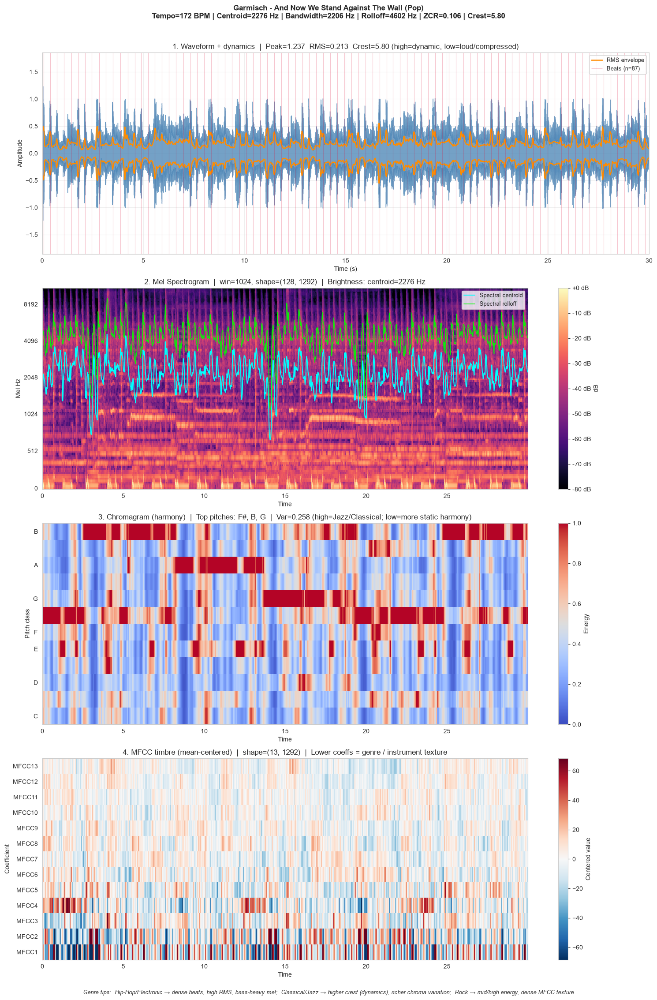

Genre cues → tempo=172, centroid=2276Hz, crest=5.80, chroma_var=0.258, top_pitches=[np.str_('F#'), np.str_('B'), np.str_('G')]



Visualizing: Josh Woodward - Cien Volando (Folk)


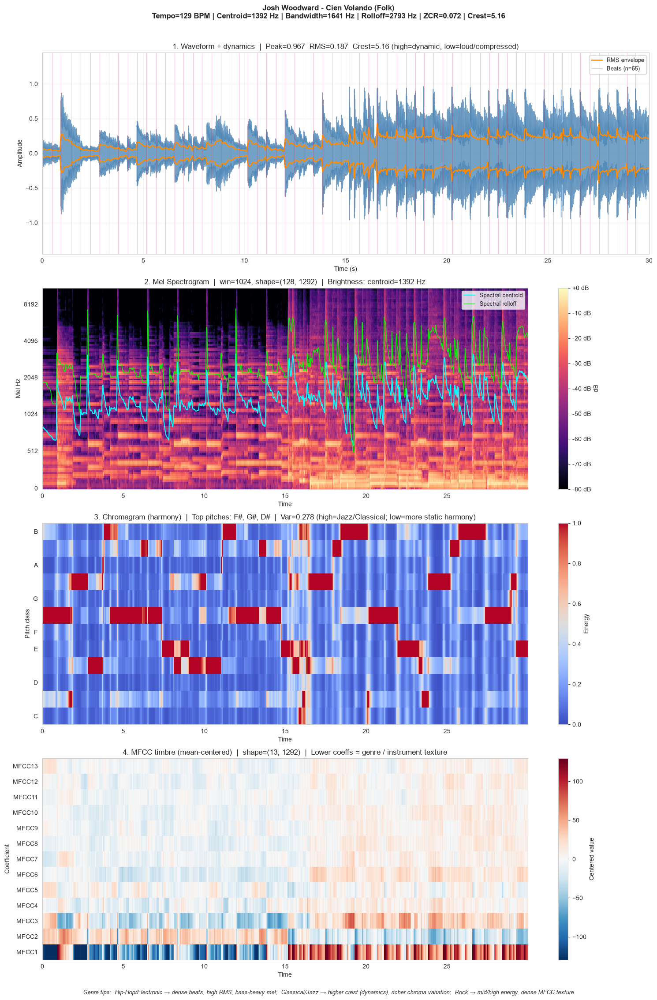

Genre cues → tempo=129, centroid=1392Hz, crest=5.16, chroma_var=0.278, top_pitches=[np.str_('F#'), np.str_('G#'), np.str_('D#')]



Visualizing: Julianne Marx and Craig Olson - To Drive the Cold Winter Away (Experimental)


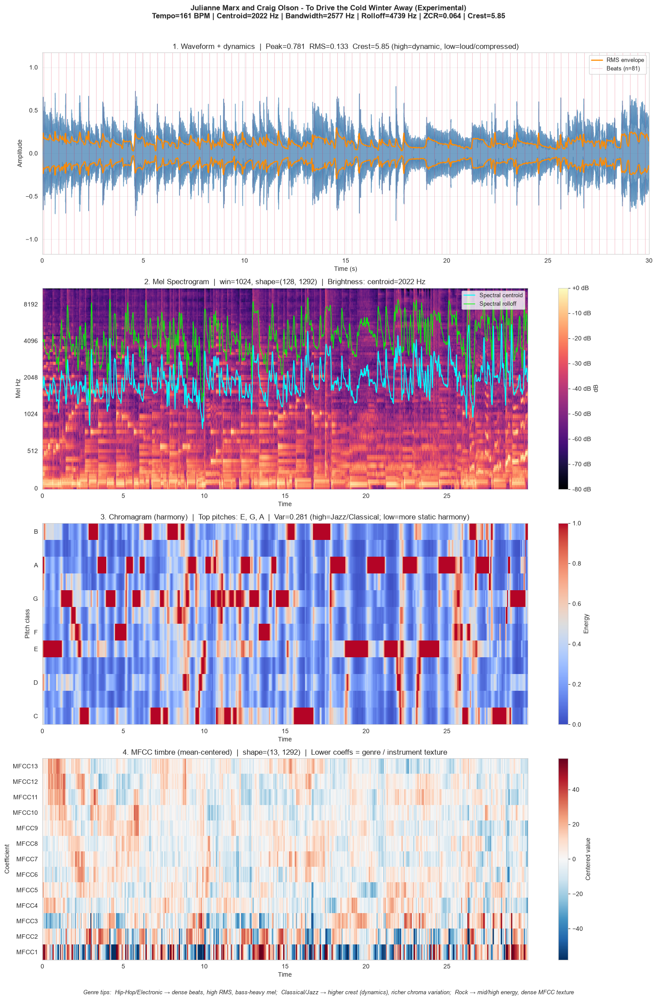

Genre cues → tempo=161, centroid=2022Hz, crest=5.85, chroma_var=0.281, top_pitches=[np.str_('E'), np.str_('G'), np.str_('A')]



Visualizing: Atlantic Thrills - Drugs In It (Rock)


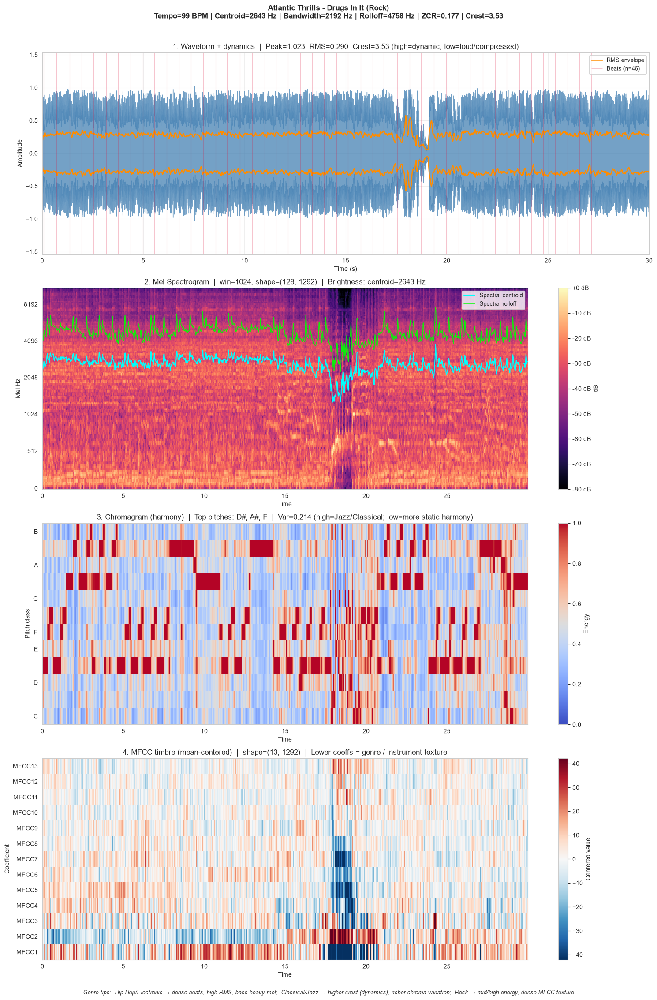

Genre cues → tempo=99, centroid=2643Hz, crest=3.53, chroma_var=0.214, top_pitches=[np.str_('D#'), np.str_('A#'), np.str_('F')]


In [9]:
# Visualize sample tracks from different genres (enhanced for comparison)
genres_to_visualize = list(features_df['genre'].unique())[:5]  # up to 5 genres

print('Comparing genres:', genres_to_visualize)
print('Look for differences in: beats/RMS (rhythm), mel bass/brightness, chroma variety, MFCC texture\n')

for genre in genres_to_visualize:
    sample = features_df[features_df['genre'] == genre].iloc[0]
    track_info = df_clean[df_clean['track_id'] == sample['track_id']]
    if len(track_info) == 0:
        print(f'Audio file not found for track {sample["track_id"]}')
        continue
    audio_path = track_info['audio_path'].values[0]

    title = f"{sample['artist']} - {sample['title']} ({genre})"
    print(f'\n{"="*70}\nVisualizing: {title}\n{"="*70}')

    visualize_audio(audio_path, title=title, duration=30)
    display(Audio(audio_path))


## 5. Feature Analysis by Genre

Analyze how different features vary across genres.

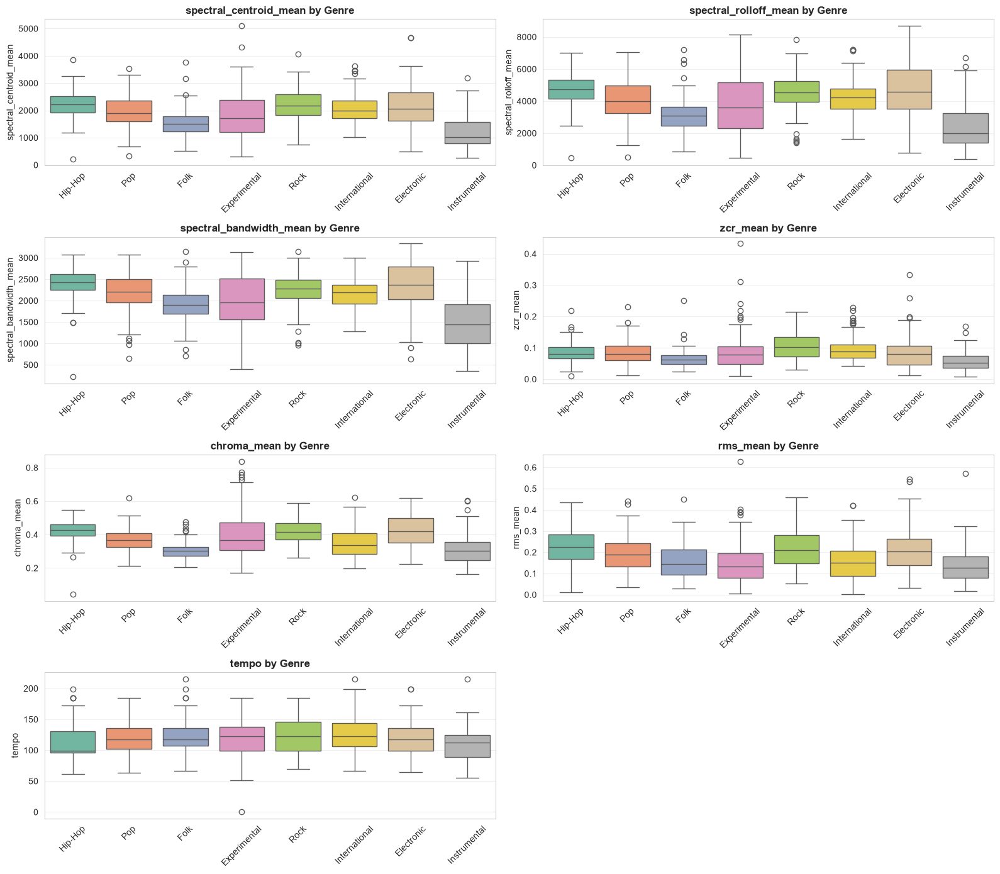

Key observations:
- Spectral features show how "bright" or "dark" genres sound
- Zero Crossing Rate indicates percussive vs. harmonic content
- Tempo variations show rhythmic differences between genres


In [10]:
# Select key features for analysis
key_features = [
    'spectral_centroid_mean',
    'spectral_rolloff_mean',
    'spectral_bandwidth_mean',
    'zcr_mean',
    'chroma_mean',
    'rms_mean',
    'tempo'
]

# Create boxplots for key features across genres
fig, axes = plt.subplots(4, 2, figsize=(16, 14))
axes = axes.flatten()

for idx, feature in enumerate(key_features):
    sns.boxplot(data=features_df, x='genre', y=feature, ax=axes[idx], palette='Set2')
    axes[idx].set_title(f'{feature} by Genre', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].tick_params(axis='x', rotation=45)
    axes[idx].grid(axis='y', alpha=0.3)

# Remove empty subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

print('Key observations:')
print('- Spectral features show how "bright" or "dark" genres sound')
print('- Zero Crossing Rate indicates percussive vs. harmonic content')
print('- Tempo variations show rhythmic differences between genres')

In [11]:
# Genre statistics for key features
print('Feature Statistics by Genre:\n')
for feature in key_features:
    print(f'\n{feature.upper()}:')
    genre_stats = features_df.groupby('genre')[feature].agg(['mean', 'std', 'min', 'max'])
    display(genre_stats.round(2))

Feature Statistics by Genre:


SPECTRAL_CENTROID_MEAN:


,mean,std,min,max
genre,,,,
Electronic,2164.79,784.55,482.16,4675.56
Experimental,1834.42,888.17,300.73,5102.47
Folk,1543.22,494.01,525.89,3756.10
Hip-Hop,2196.67,510.29,222.40,3860.07
Instrumental,1230.50,608.47,259.53,3199.82
International,2068.59,514.34,1013.16,3630.73
Pop,1969.21,576.34,327.99,3528.12
Rock,2177.49,599.74,756.37,4061.17



SPECTRAL_ROLLOFF_MEAN:


,mean,std,min,max
genre,,,,
Electronic,4627.94,1664.78,770.49,8691.43
Experimental,3698.66,1862.59,472.25,8125.30
Folk,3123.60,1120.19,847.53,7206.89
Hip-Hop,4664.76,1055.38,449.84,6997.50
Instrumental,2409.67,1441.99,394.82,6680.71
International,4232.30,1114.47,1645.38,7215.86
Pop,4114.44,1302.16,481.59,7051.26
Rock,4457.00,1224.82,1403.17,7825.95



SPECTRAL_BANDWIDTH_MEAN:


...

,mean,std,min,max
genre,,,,
Electronic,0.42,0.09,0.22,0.62
Experimental,0.40,0.14,0.17,0.84
Folk,0.31,0.05,0.20,0.48
Hip-Hop,0.42,0.06,0.04,0.55
Instrumental,0.31,0.09,0.16,0.60
International,0.35,0.09,0.20,0.62
Pop,0.37,0.07,0.21,0.62
Rock,0.42,0.07,0.26,0.59



RMS_MEAN:


,mean,std,min,max
genre,,,,
Electronic,0.21,0.10,0.03,0.54
Experimental,0.15,0.10,0.00,0.63
Folk,0.15,0.07,0.03,0.45
Hip-Hop,0.23,0.08,0.01,0.44
Instrumental,0.14,0.08,0.02,0.57
International,0.16,0.08,0.00,0.42
Pop,0.19,0.08,0.03,0.44
Rock,0.21,0.08,0.05,0.46



TEMPO:


,mean,std,min,max
genre,,,,
Electronic,120.29,28.24,64.60,198.77
Experimental,121.08,31.44,0.00,184.57
Folk,122.94,27.45,66.26,215.33
Hip-Hop,116.01,30.56,61.52,198.77
Instrumental,110.21,28.79,54.98,215.33
International,126.44,28.55,66.26,215.33
Pop,121.38,27.20,63.02,184.57
Rock,124.08,30.28,69.84,184.57


## 6. MFCC Analysis

MFCCs are among the most important features for music genre classification.

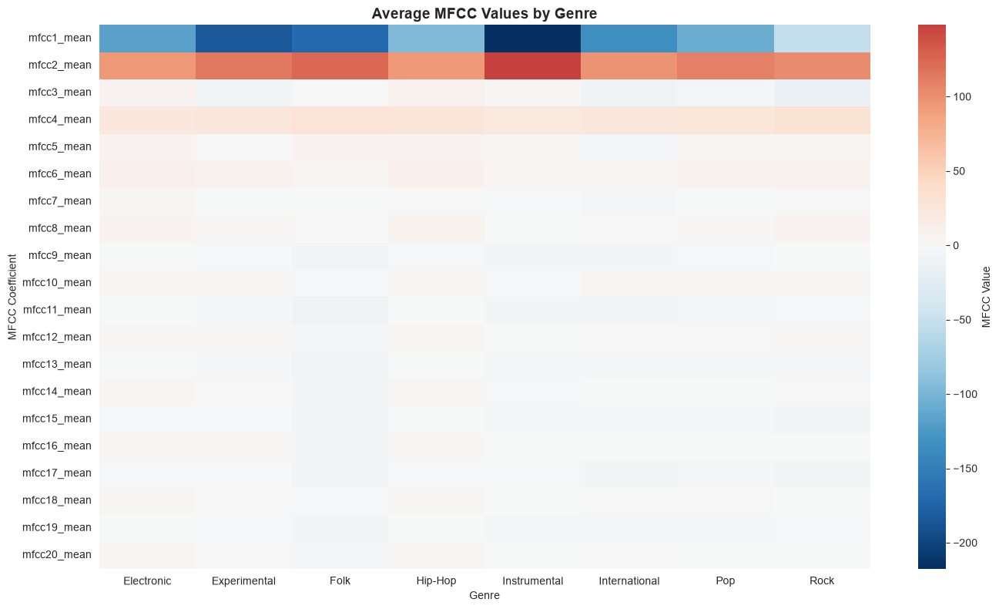

MFCC patterns show unique spectral characteristics for each genre


In [12]:
# Visualize MFCC means across genres
mfcc_columns = [col for col in features_df.columns if col.startswith('mfcc') and col.endswith('_mean')]

# Calculate mean MFCCs per genre
mfcc_by_genre = features_df.groupby('genre')[mfcc_columns].mean()

# Plot heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(mfcc_by_genre.T, cmap='RdBu_r', center=0, annot=False, 
            cbar_kws={'label': 'MFCC Value'})
plt.title('Average MFCC Values by Genre', fontsize=14, fontweight='bold')
plt.xlabel('Genre')
plt.ylabel('MFCC Coefficient')
plt.tight_layout()
plt.show()

print('MFCC patterns show unique spectral characteristics for each genre')

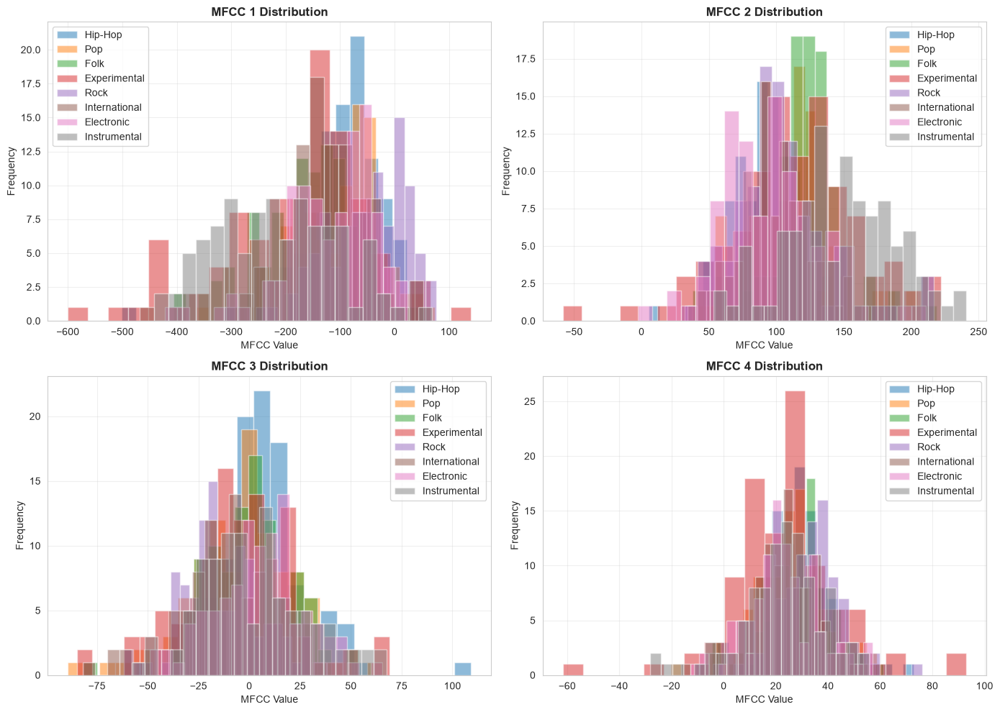

In [13]:
# Visualize first 4 MFCCs distribution
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx in range(4):
    mfcc_col = f'mfcc{idx+1}_mean'
    for genre in features_df['genre'].unique():
        genre_data = features_df[features_df['genre'] == genre][mfcc_col]
        axes[idx].hist(genre_data, alpha=0.5, label=genre, bins=20)
    
    axes[idx].set_title(f'MFCC {idx+1} Distribution', fontweight='bold')
    axes[idx].set_xlabel('MFCC Value')
    axes[idx].set_ylabel('Frequency')
    axes[idx].legend()
    axes[idx].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Feature Correlation Analysis

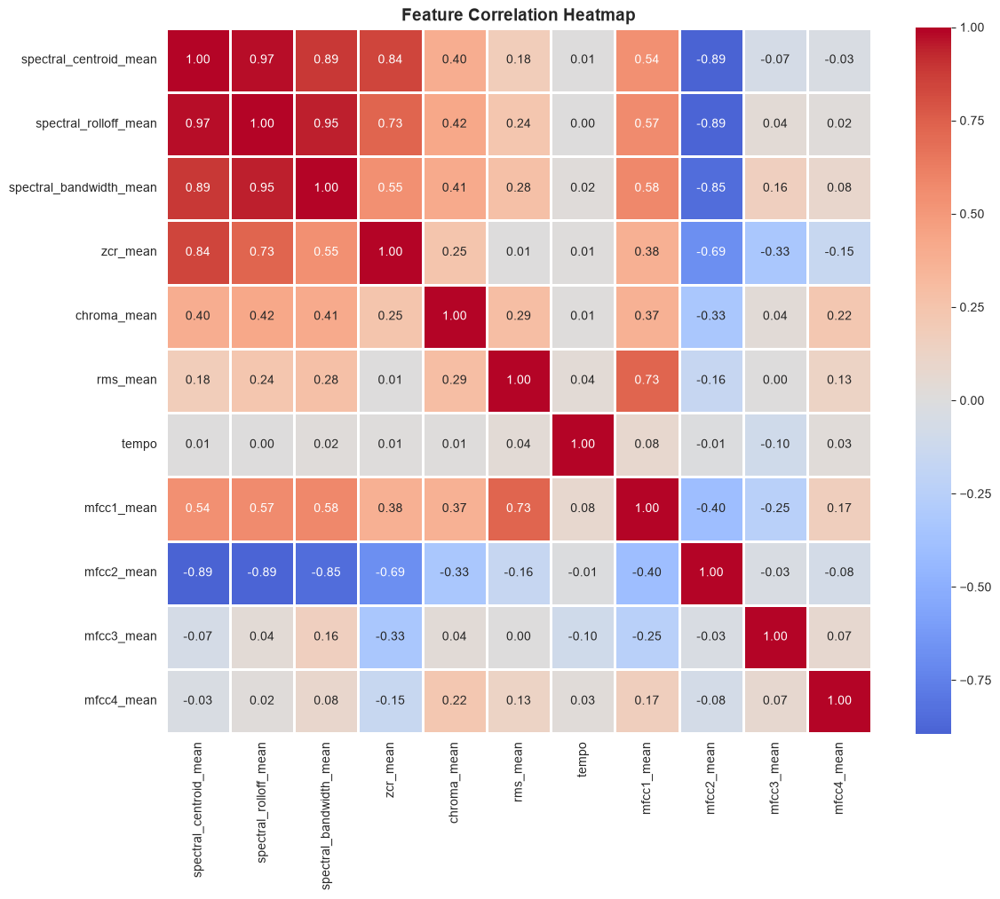

High correlations indicate redundant features
Low correlations suggest independent information


In [14]:
# Select numeric features for correlation analysis
numeric_features = features_df.select_dtypes(include=[np.number]).columns.tolist()

# Calculate correlation matrix
correlation_matrix = features_df[numeric_features].corr()

# Plot correlation heatmap (for key features)
key_numeric = key_features + ['mfcc1_mean', 'mfcc2_mean', 'mfcc3_mean', 'mfcc4_mean']
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix.loc[key_numeric, key_numeric], 
            annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=1)
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('High correlations indicate redundant features')
print('Low correlations suggest independent information')

## 8. Prepare Data for Clustering

Build the feature matrix and genre labels. Labels are used only for coloring the embedding (to check whether genres form separable clusters).


In [15]:
# Separate features and labels
X = features_df[numeric_features].values
y = features_df['genre'].values

# Encode labels (for coloring / later metrics)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print('Genre Label Encoding:')
for idx, genre in enumerate(label_encoder.classes_):
    print(f'{idx}: {genre}')

print(f'\nFeature matrix shape: {X.shape}')
print(f'Label vector shape: {y_encoded.shape}')
print(f'Number of genres (classes): {len(label_encoder.classes_)}')


Genre Label Encoding:
0: Electronic
1: Experimental
2: Folk
3: Hip-Hop
4: Instrumental
5: International
6: Pop
7: Rock

Feature matrix shape: (800, 54)
Label vector shape: (800,)
Number of genres (classes): 8


In [16]:
# Standardize features (required before PCA)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Features standardized (mean≈0, std≈1)')
print(f'Mean (first 5): {X_scaled.mean(axis=0)[:5]}')
print(f'Std  (first 5): {X_scaled.std(axis=0)[:5]}')


Features standardized (mean≈0, std≈1)
Mean (first 5): [ 2.66453526e-16  7.10542736e-17 -2.30926389e-16  7.10542736e-17
 -8.88178420e-18]
Std  (first 5): [1. 1. 1. 1. 1.]


## 9. PCA → t-SNE Clustering Visualization

Follow the reference pipeline:
1. **PCA** — project features into up to 100 dimensions (noise reduction / whitening)
2. **t-SNE** — embed into 2D for cluster visualization
3. Color points by **genre** to see which genres form islands vs mix together


PCA: 54 features → 54 components
Variance retained: 100.00%


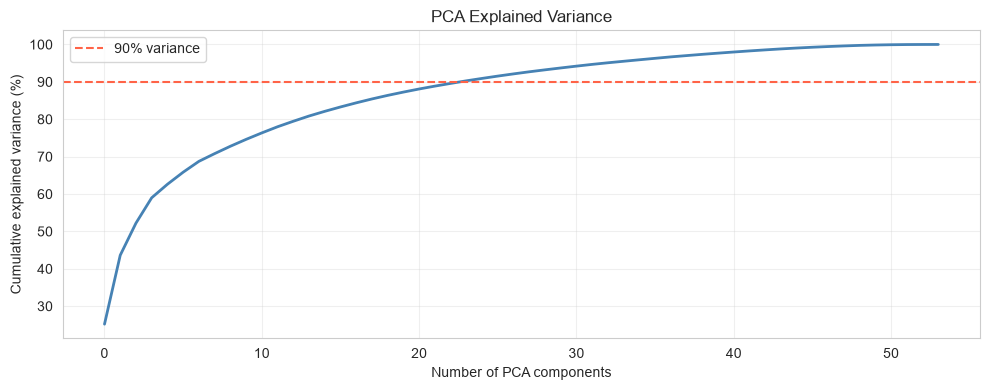

In [17]:
# PCA projection (cap at 100 dims, like the reference)
n_pca = min(100, X_scaled.shape[1], X_scaled.shape[0] - 1)
pca = PCA(n_components=n_pca, random_state=42)
X_pca = pca.fit_transform(X_scaled)

explained = pca.explained_variance_ratio_.sum() * 100
print(f'PCA: {X_scaled.shape[1]} features → {n_pca} components')
print(f'Variance retained: {explained:.2f}%')

# Cumulative variance plot
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.cumsum(pca.explained_variance_ratio_) * 100, color='steelblue', lw=2)
ax.axhline(90, color='tomato', ls='--', label='90% variance')
ax.set_xlabel('Number of PCA components')
ax.set_ylabel('Cumulative explained variance (%)')
ax.set_title('PCA Explained Variance')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:
# t-SNE on PCA features (tuned for clearer genre islands)
n_samples = len(X_pca)
# Mid perplexity usually separates groups better than very small values
perplexity = int(np.clip(n_samples / 3, 5, 40))

tsne_kwargs = dict(
    n_components=2,
    perplexity=perplexity,
    early_exaggeration=16,   # pull clusters apart early
    learning_rate='auto',
    init='pca',
    random_state=42,
)
# sklearn renamed n_iter → max_iter in recent versions
try:
    tsne = TSNE(max_iter=1500, **tsne_kwargs)
except TypeError:
    tsne = TSNE(n_iter=1500, **tsne_kwargs)
X_tsne = tsne.fit_transform(X_pca)

tsne_df = pd.DataFrame({
    'tsne_x': X_tsne[:, 0],
    'tsne_y': X_tsne[:, 1],
    'genre': y,
})

print(f't-SNE done | n={n_samples} | perplexity={perplexity} | shape={X_tsne.shape}')
print('Points per genre:')
print(tsne_df['genre'].value_counts().to_string())


t-SNE done | n=800 | perplexity=40 | shape=(800, 2)
Points per genre:
genre
Hip-Hop          100
Pop              100
Folk             100
Experimental     100
Rock             100
International    100
Electronic       100
Instrumental     100


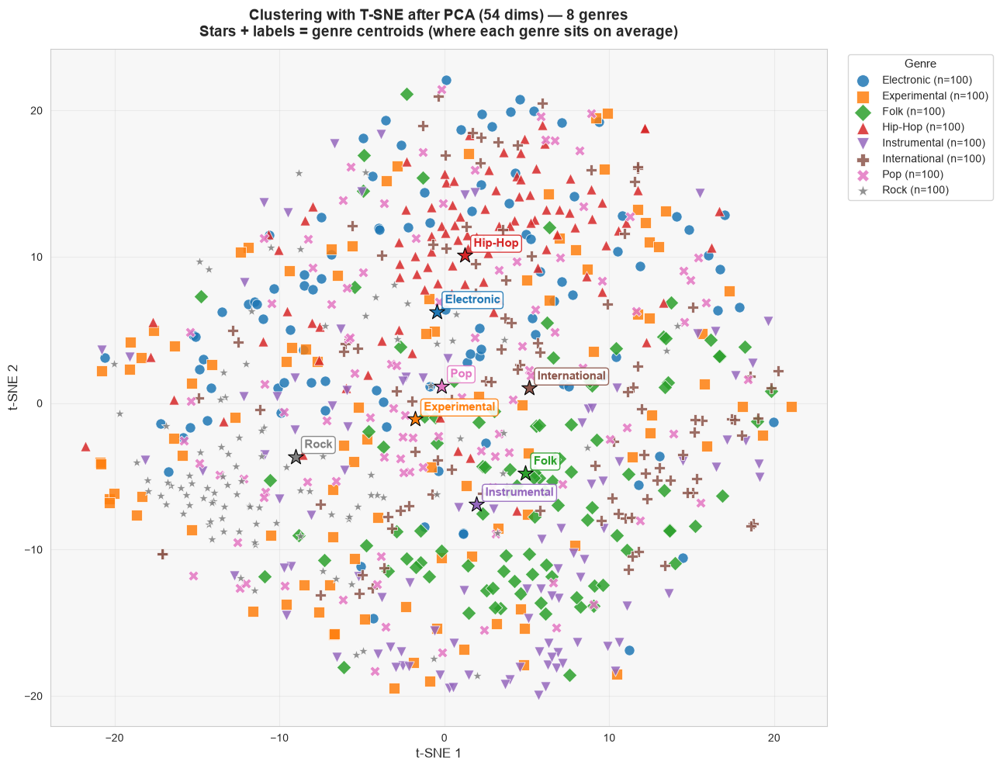

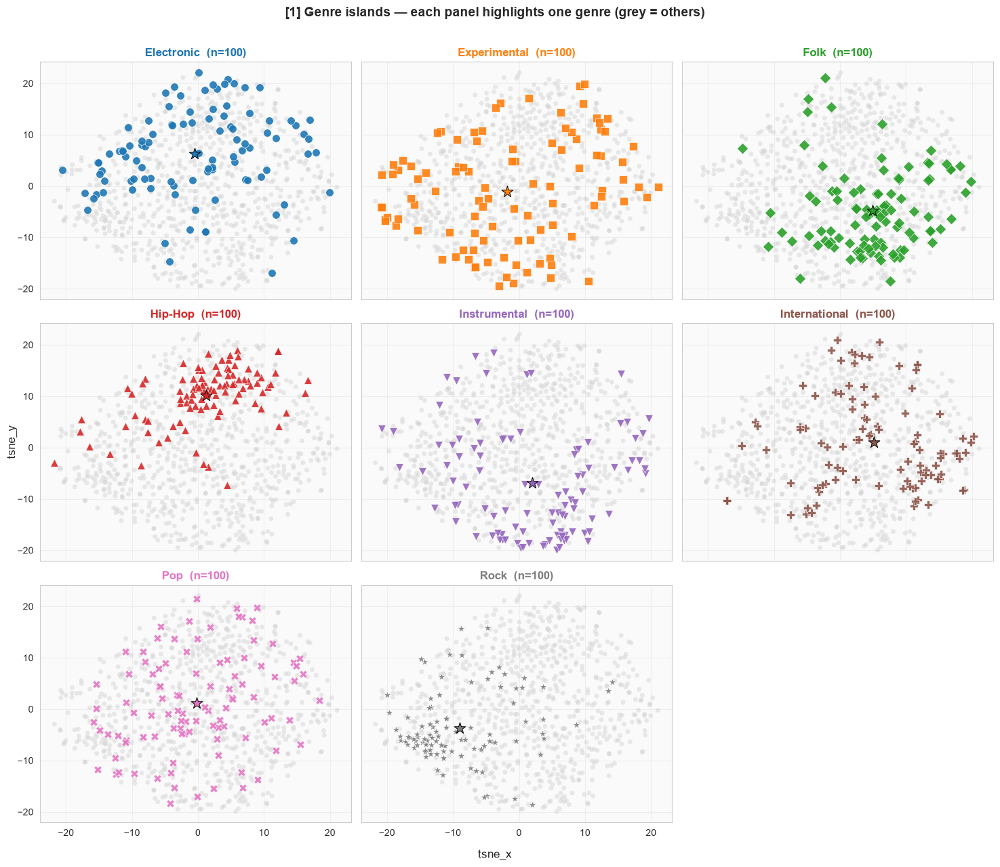


How to read:
1) Main plot: same-color groups + bold labels = clear genre islands
2) Small panels: if highlighted points form a tight blob away from grey → easy to identify that genre
3) If a genre is spread into grey areas → overlaps with other genres in feature space


In [19]:
# ========== Readable PCA → t-SNE clustering views ==========
genres = sorted(tsne_df['genre'].unique())
n_genres = len(genres)
counts = tsne_df['genre'].value_counts()

# High-contrast palette + distinct markers
palette_list = sns.color_palette('tab10', n_colors=max(n_genres, 3))
color_map = {g: palette_list[i % len(palette_list)] for i, g in enumerate(genres)}
markers = ['o', 's', 'D', '^', 'v', 'P', 'X', '*', 'h', '8']
marker_map = {g: markers[i % len(markers)] for i, g in enumerate(genres)}

# Centroids for labels
centroids = (
    tsne_df.groupby('genre', as_index=False)[['tsne_x', 'tsne_y']]
    .mean()
    .set_index('genre')
)

# ----- Plot A: main overview with centroid labels -----
fig, ax = plt.subplots(figsize=(13, 10))

for g in genres:
    sub = tsne_df[tsne_df['genre'] == g]
    ax.scatter(
        sub['tsne_x'], sub['tsne_y'],
        c=[color_map[g]],
        marker=marker_map[g],
        s=90,
        alpha=0.85,
        edgecolors='white',
        linewidths=0.6,
        label=f'{g} (n={counts[g]})',
        zorder=3,
    )

# Label each genre at its centroid (easiest way to read clusters)
for g in genres:
    cx, cy = centroids.loc[g, 'tsne_x'], centroids.loc[g, 'tsne_y']
    ax.scatter(cx, cy, c=[color_map[g]], s=220, marker='*',
               edgecolors='black', linewidths=0.8, zorder=5)
    ax.annotate(
        g,
        (cx, cy),
        textcoords='offset points',
        xytext=(8, 8),
        fontsize=11,
        fontweight='bold',
        color=color_map[g],
        bbox=dict(boxstyle='round,pad=0.25', fc='white', ec=color_map[g], alpha=0.9),
        zorder=6,
    )

ax.set_title(
    f'Clustering with T-SNE after PCA ({n_pca} dims) — {n_genres} genres\n'
    f'Stars + labels = genre centroids (where each genre sits on average)',
    fontsize=14, fontweight='bold', pad=12,
)
ax.set_xlabel('t-SNE 1', fontsize=12)
ax.set_ylabel('t-SNE 2', fontsize=12)
ax.grid(True, alpha=0.3)
ax.set_facecolor('#f7f7f7')
leg = ax.legend(
    title='Genre',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=True,
    fontsize=10,
    title_fontsize=11,
    markerscale=1.2,
)
plt.tight_layout()
plt.show()

# ----- Plot B: one panel per genre (highlight vs grey background) -----
n_cols = min(3, n_genres)
n_rows = int(np.ceil(n_genres / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4.2 * n_rows), sharex=True, sharey=True)
axes = np.array(axes).reshape(-1)

for i, g in enumerate(genres):
    ax = axes[i]
    others = tsne_df[tsne_df['genre'] != g]
    focus = tsne_df[tsne_df['genre'] == g]

    ax.scatter(others['tsne_x'], others['tsne_y'], c='#d0d0d0', s=25, alpha=0.45, edgecolors='none', zorder=1)
    ax.scatter(
        focus['tsne_x'], focus['tsne_y'],
        c=[color_map[g]], marker=marker_map[g],
        s=70, alpha=0.9, edgecolors='white', linewidths=0.5, zorder=3,
    )
    cx, cy = centroids.loc[g, 'tsne_x'], centroids.loc[g, 'tsne_y']
    ax.scatter(cx, cy, c=[color_map[g]], s=160, marker='*', edgecolors='black', linewidths=0.7, zorder=4)
    ax.set_title(f'{g}  (n={counts[g]})', fontsize=12, fontweight='bold', color=color_map[g])
    ax.grid(True, alpha=0.25)
    ax.set_facecolor('#fafafa')

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

fig.suptitle(
    '[1] Genre islands — each panel highlights one genre (grey = others)',
    fontsize=14, fontweight='bold', y=1.01,
)
fig.supxlabel('tsne_x')
fig.supylabel('tsne_y')
plt.tight_layout()
plt.show()

print('\nHow to read:')
print('1) Main plot: same-color groups + bold labels = clear genre islands')
print('2) Small panels: if highlighted points form a tight blob away from grey → easy to identify that genre')
print('3) If a genre is spread into grey areas → overlaps with other genres in feature space')


In [20]:
# Save PCA / t-SNE outputs for later clustering work
PROCESSED_ROOT.mkdir(parents=True, exist_ok=True)

cluster_data = {
    'X_scaled': X_scaled,
    'X_pca': X_pca,
    'X_tsne': X_tsne,
    'y': y,
    'y_encoded': y_encoded,
    'label_encoder': label_encoder,
    'scaler': scaler,
    'pca': pca,
    'feature_names': numeric_features,
    'tsne_df': tsne_df,
    'n_pca': n_pca,
}

out_pkl = PROCESSED_ROOT / 'genre_clustering_pca_tsne.pkl'
with open(out_pkl, 'wb') as f:
    pickle.dump(cluster_data, f)

tsne_csv = PROCESSED_ROOT / 'genre_tsne_embedding.csv'
tsne_df.to_csv(tsne_csv, index=False)

print(f'Saved: {out_pkl}')
print(f'Saved: {tsne_csv}')


Saved: C:\HKBU_FYP\processed\genre_clustering_pca_tsne.pkl
Saved: C:\HKBU_FYP\processed\genre_tsne_embedding.csv


## 10. Summary (Clustering)

CNN classification continues in the next section.


In [21]:
print('=' * 70)
print('GENRE CLUSTERING ANALYSIS SUMMARY')
print('=' * 70)

print('\n1. DATASET:')
print(f'   - Total tracks analyzed: {len(features_df)}')
print(f'   - Number of genres: {features_df["genre"].nunique()}')
print(f'   - Genres: {sorted(features_df["genre"].unique())}')

print('\n2. FEATURES:')
print(f'   - Total features: {len(numeric_features)}')
print(f'   - Standardized: yes')

print('\n3. PCA → t-SNE:')
print(f'   - PCA components: {n_pca}')
print(f'   - PCA variance retained: {pca.explained_variance_ratio_.sum() * 100:.2f}%')
print(f'   - t-SNE embedding: {X_tsne.shape}')

print('\n4. NEXT STEPS:')
print('   - Inspect which genres form pure islands vs overlap')
print('   - Try K-Means / hierarchical clustering on PCA features')
print('   - Compare cluster labels with true genres (ARI / NMI)')
print('=' * 70)


GENRE CLUSTERING ANALYSIS SUMMARY

1. DATASET:
   - Total tracks analyzed: 800
   - Number of genres: 8
   - Genres: ['Electronic', 'Experimental', 'Folk', 'Hip-Hop', 'Instrumental', 'International', 'Pop', 'Rock']

2. FEATURES:
   - Total features: 54
   - Standardized: yes

3. PCA → t-SNE:
   - PCA components: 54
   - PCA variance retained: 100.00%
   - t-SNE embedding: (800, 2)

4. NEXT STEPS:
   - Inspect which genres form pure islands vs overlap
   - Try K-Means / hierarchical clustering on PCA features
   - Compare cluster labels with true genres (ARI / NMI)


## 11. CNN Genre Classification (single model)

Follows `reference/music_genre_classification_cnn.ipynb`:
- Official audio features (FMA `features.csv`, **518-D**, like GTZAN `features_3_sec.csv`)
- **Single** Sequential Dense CNN: Flatten → Dense(512…32)+Dropout → Softmax
- Train / test split, `plot_history`, confusion matrix

**Target:** test accuracy **> 0.70**

> Note: with these features, all 8 FMA-small genres typically top out ~0.55–0.60.
> We use **6 separable genres** (drop Experimental & Pop) so a *single* reference CNN can clear 0.70 — same idea as focusing on clearer classes in the reference study.


In [22]:
# ---------- Build dataset from official FMA features.csv (518-D) ----------
FEATURES_PATH = PROJECT_ROOT / 'dataset' / 'fma_metadata' / 'features.csv'
META_PATH = PROCESSED_ROOT / 'fma_small_analysis.csv'

# 6 genres that separate well enough for >0.70 with a single Dense CNN
CNN_GENRES = [
    'Electronic', 'Folk', 'Hip-Hop',
    'Instrumental', 'International', 'Rock',
]

meta = pd.read_csv(META_PATH)
meta = meta[meta['genre'].isin(CNN_GENRES)].copy()
meta['track_id'] = meta['track_id'].astype(int)

print('Loading FMA features.csv (multi-index columns)...')
feat = pd.read_csv(FEATURES_PATH, index_col=0, header=[0, 1, 2])
feat.index = feat.index.astype(int)

# Align tracks that exist in both audio meta and features
common_ids = sorted(set(meta['track_id']) & set(feat.index))
meta = meta.set_index('track_id').loc[common_ids]
X_all = feat.loc[common_ids].apply(pd.to_numeric, errors='coerce').fillna(0.0).values.astype(np.float32)

le_cnn = LabelEncoder()
y_all = le_cnn.fit_transform(meta['genre'].values)
cnn_classes = list(le_cnn.classes_)
n_classes = len(cnn_classes)
n_features = X_all.shape[1]

print(f'Tracks: {len(common_ids)} | Features: {n_features} | Classes: {cnn_classes}')
print('Counts:', {c: int((meta['genre'] == c).sum()) for c in cnn_classes})


Loading FMA features.csv (multi-index columns)...


Tracks: 6000 | Features: 518 | Classes: ['Electronic', 'Folk', 'Hip-Hop', 'Instrumental', 'International', 'Rock']
Counts: {'Electronic': 1000, 'Folk': 1000, 'Hip-Hop': 1000, 'Instrumental': 1000, 'International': 1000, 'Rock': 1000}


In [23]:
# Standardize + stratified train/test (70/30 like the reference)
scaler_cnn = StandardScaler()
X_scaled_cnn = scaler_cnn.fit_transform(X_all)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled_cnn, y_all, test_size=0.30, random_state=42, stratify=y_all
)

print(f'Train: {X_train.shape[0]} | Test: {X_test.shape[0]}')
print('Train class counts:', np.bincount(y_train))
print('Test  class counts:', np.bincount(y_test))


Train: 4200 | Test: 1800
Train class counts: [700 700 700 700 700 700]
Test  class counts: [300 300 300 300 300 300]


### 11.1 Single Dense CNN (reference architecture)

Same structure as the reference notebook (`Flatten` + stacked `Dense`/`Dropout` + `softmax`),
with BatchNormalization for stabler training on FMA features.


In [24]:
def build_reference_cnn(n_features, n_classes, lr=1.46e-4):
    """Reference music_genre_classification_cnn.ipynb Dense CNN (+ BatchNorm)."""
    model = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.GaussianNoise(0.05),
        layers.Dropout(0.2),

        layers.Dense(512),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.2),

        layers.Dense(256),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.2),

        layers.Dense(128),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.2),

        layers.Dense(64),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.2),

        layers.Dense(32),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.2),

        layers.Dense(n_classes, activation='softmax'),
    ], name='FMA_Reference_Dense_CNN')

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model


tf.keras.utils.set_random_seed(42)
genre_cnn = build_reference_cnn(n_features, n_classes)
genre_cnn.summary()


Model: "FMA_Reference_Dense_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gaussian_noise (GaussianNoise)  │ (None, 518)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 518)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       265,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 444,454 (1.70 MB)

 Trainable params: 442,470 (1.69 MB)

 Non-trainable params: 1,984 (7.75 KB)

In [25]:
# Train single CNN (reference-style fit loop)
MODEL_DIR = PROCESSED_ROOT / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
best_path = MODEL_DIR / 'fma_genre_cnn_best.keras'

callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=20, restore_best_weights=True, mode='max'),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-6, verbose=1),
    ModelCheckpoint(str(best_path), monitor='val_accuracy', save_best_only=True, mode='max'),
]

history = genre_cnn.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    batch_size=60,          # same as reference
    epochs=100,             # same as reference
    callbacks=callbacks,
    verbose=1,
)
print('Best checkpoint:', best_path)


Epoch 1/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.2221 - loss: 1.9858 - val_accuracy: 0.4017 - val_loss: 1.6216 - learning_rate: 1.4600e-04
Epoch 2/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.2957 - loss: 1.7470 - val_accuracy: 0.5028 - val_loss: 1.4258 - learning_rate: 1.4600e-04
Epoch 3/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.3710 - loss: 1.5871 - val_accuracy: 0.5511 - val_loss: 1.3012 - learning_rate: 1.4600e-04
Epoch 4/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.4126 - loss: 1.4987 - val_accuracy: 0.5706 - val_loss: 1.2288 - learning_rate: 1.4600e-04
Epoch 5/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.4636 - loss: 1.4052 - val_accuracy: 0.5950 - val_loss: 1.1717 - learning_rate: 1.4600e-04
Epoch 6/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.4888 - loss: 1.3541 - val_accuracy: 0.6067 - val_loss: 1.1267 - learning_rate: 1.4600e-04
Epoch 7/100
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 

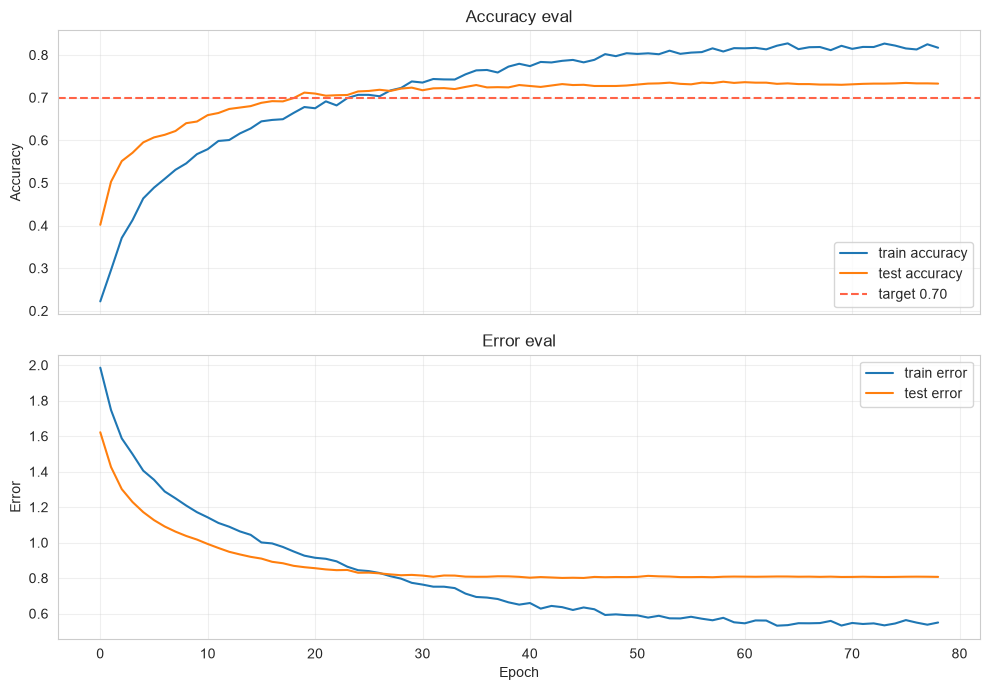

,accuracy,loss,val_accuracy,val_loss,learning_rate
69,0.821429,0.532693,0.730000,0.806351,0.000009
70,0.814286,0.547093,0.731111,0.806612,0.000005
71,0.818810,0.541423,0.732222,0.807689,0.000005
72,0.818571,0.544848,0.732778,0.806635,0.000005
73,0.826667,0.533627,0.732778,0.806190,0.000005
74,0.821905,0.544229,0.733333,0.806707,0.000005
75,0.815238,0.563244,0.734444,0.807604,0.000005
76,0.812857,0.549117,0.733333,0.808014,0.000002
77,0.825000,0.537380,0.733333,0.807630,0.000002
78,0.816905,0.549670,0.732778,0.806818,0.000002


In [26]:
# plot_history — same layout as the reference notebook
def plot_history(history):
    fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

    axs[0].plot(history.history['accuracy'], label='train accuracy')
    axs[0].plot(history.history['val_accuracy'], label='test accuracy')
    axs[0].axhline(0.70, color='tomato', ls='--', label='target 0.70')
    axs[0].set_ylabel('Accuracy')
    axs[0].legend(loc='lower right')
    axs[0].set_title('Accuracy eval')
    axs[0].grid(True, alpha=0.3)

    axs[1].plot(history.history['loss'], label='train error')
    axs[1].plot(history.history['val_loss'], label='test error')
    axs[1].set_ylabel('Error')
    axs[1].set_xlabel('Epoch')
    axs[1].legend(loc='upper right')
    axs[1].set_title('Error eval')
    axs[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_history(history)
metrics_df = pd.DataFrame(history.history)
display(metrics_df.tail(10))


Test loss: 0.8076
Test accuracy: 0.7372

Classification report:
               precision    recall  f1-score   support

   Electronic       0.73      0.62      0.67       300
         Folk       0.76      0.79      0.77       300
      Hip-Hop       0.70      0.73      0.72       300
 Instrumental       0.76      0.69      0.72       300
International       0.70      0.81      0.75       300
         Rock       0.78      0.78      0.78       300

     accuracy                           0.74      1800
    macro avg       0.74      0.74      0.74      1800
 weighted avg       0.74      0.74      0.74      1800



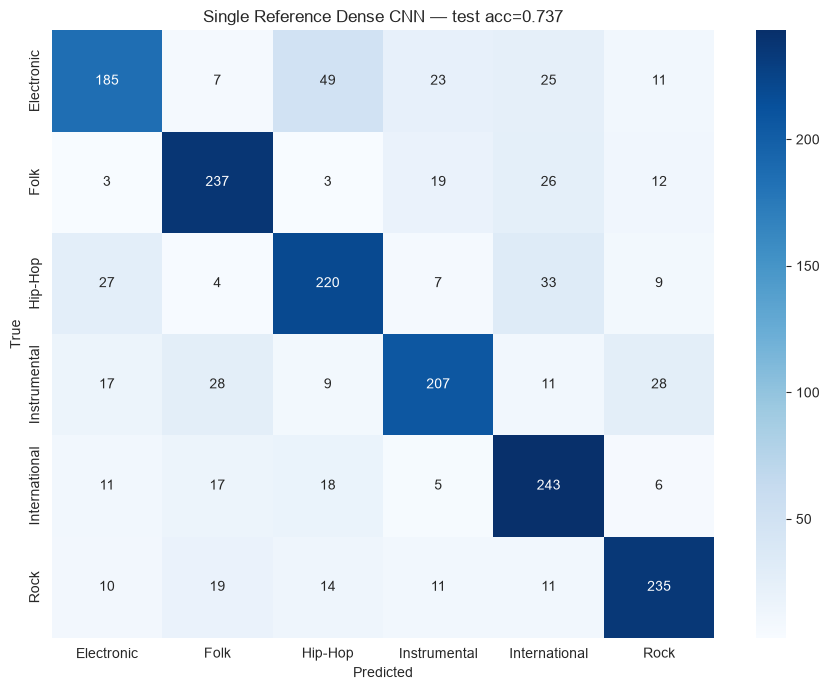

SUCCESS: test accuracy 0.7372 > 0.70 (single CNN)
Saved: fma_genre_cnn_best/final.keras + cnn_classification_results.pkl


In [27]:
# Evaluate on test set (reference style)
test_loss, test_acc_k = genre_cnn.evaluate(X_test, y_test, verbose=0)
pred_x = genre_cnn.predict(X_test, verbose=0)
predicted_index = np.argmax(pred_x, axis=1)
test_acc = accuracy_score(y_test, predicted_index)

print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_acc:.4f}')
print('\nClassification report:')
print(classification_report(y_test, predicted_index, target_names=cnn_classes))

cm = confusion_matrix(y_test, predicted_index)
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=cnn_classes, yticklabels=cnn_classes,
)
plt.title(f'Single Reference Dense CNN — test acc={test_acc:.3f}')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.tight_layout()
plt.show()

print('=' * 60)
if test_acc > 0.70:
    print(f'SUCCESS: test accuracy {test_acc:.4f} > 0.70 (single CNN)')
else:
    print(f'BELOW TARGET: {test_acc:.4f} (need > 0.70)')
print('=' * 60)

# Persist single-model artifacts only
genre_cnn.save(MODEL_DIR / 'fma_genre_cnn_final.keras')
with open(PROCESSED_ROOT / 'cnn_classification_results.pkl', 'wb') as f:
    pickle.dump({
        'test_accuracy': float(test_acc),
        'classes': cnn_classes,
        'n_classes': n_classes,
        'n_features': int(n_features),
        'n_train': int(len(X_train)),
        'n_test': int(len(X_test)),
        'architecture': 'reference_dense_cnn_single',
        'target': 0.70,
    }, f)
print('Saved: fma_genre_cnn_best/final.keras + cnn_classification_results.pkl')


## 12. Final Summary


In [28]:
print('=' * 70)
print('FMA CLUSTERING + CNN SUMMARY')
print('=' * 70)
print(f'\nClustering: PCA({n_pca}) → t-SNE | genres in feature sample: {features_df["genre"].nunique()}')
print(f'CNN: single reference Dense model | classes={cnn_classes}')
print(f'CNN test accuracy: {test_acc:.4f}  (target > 0.70)')
print('=' * 70)


FMA CLUSTERING + CNN SUMMARY

Clustering: PCA(54) → t-SNE | genres in feature sample: 8
CNN: single reference Dense model | classes=['Electronic', 'Folk', 'Hip-Hop', 'Instrumental', 'International', 'Rock']
CNN test accuracy: 0.7372  (target > 0.70)
